# Understanding Healthcare Data: From Raw Data to AI-Ready

**Learning outcomes**
1. Understand patient, encounter, diagnosis/finding, observation, medication, and procedure data.
2. Investigate data quality, relationships, and clinical normalization.
3. Create simple, time-aware features and see how a fictional clinical note becomes structured information.

> **Scope:** All CSV results come from your **locally generated Synthea population**. The short clinical-note and unit-conversion demonstrations are explicitly marked as **illustrative examples**, not records from the CSV files. This is educational material, not a clinically validated system.

## 0. Setup — before the session

From your Synthea repository, export CSV files:

```bash
./run_synthea -s 12345 -p 100 --exporter.csv.export=true
```

Place this notebook in the `synthea/` folder (next to `output/`) or set `CSV_DIR_OVERRIDE` below. Install the notebook dependencies:

```bash
python3 -m pip install jupyter pandas numpy matplotlib ipykernel
jupyter notebook understanding_healthcare_data_maven.ipynb
```

Required files: `patients.csv`, `encounters.csv`, `conditions.csv`, `observations.csv`, `medications.csv`, `procedures.csv`.

## 1. Load the healthcare data

In [1]:
from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

# Keep None when notebook is inside the Synthea project.
# Otherwise set an absolute folder path, e.g. "/Users/you/synthea/output/csv".
CSV_DIR_OVERRIDE = "/Users/lakshmi/synthea/output/csv"
required_names = ["patients", "encounters", "conditions", "observations", "medications", "procedures"]
candidates = []
if CSV_DIR_OVERRIDE:
    candidates.append(Path(CSV_DIR_OVERRIDE).expanduser())
if os.environ.get("SYNTHEA_CSV_DIR"):
    candidates.append(Path(os.environ["SYNTHEA_CSV_DIR"]).expanduser())
candidates += [
    Path("output/csv"), Path("../output/csv"),
    Path("synthea/output/csv"), Path("../synthea/output/csv"),
    Path.home() / "synthea/output/csv"
]
csv_dir = next((p.resolve() for p in candidates if all((p / f"{n}.csv").is_file() for n in required_names)), None)
if csv_dir is None:
    raise FileNotFoundError("Six Synthea CSVs not found. Set CSV_DIR_OVERRIDE to the folder containing patients.csv etc.")
print("Using Synthea data from:", csv_dir)

Using Synthea data from: /Users/lakshmi/synthea/output/csv


In [2]:
# IDs, terminology codes, and observation values are read as text.
text_columns = {"Id":"string", "PATIENT":"string", "ENCOUNTER":"string", "CODE":"string",
                "SYSTEM":"string", "VALUE":"string", "ZIP":"string", "FIPS":"string"}
tables = {
    name: pd.read_csv(csv_dir / f"{name}.csv", dtype=text_columns, low_memory=False)
    for name in required_names
}
patients, encounters, conditions, observations, medications, procedures = (
    tables[name] for name in required_names
)
summary = pd.DataFrame([
    {"dataset": name, "records": len(df), "columns": len(df.columns),
     "patients_represented": df["Id"].nunique() if name == "patients" else df["PATIENT"].nunique()}
    for name, df in tables.items()
])
display(summary)

,dataset,records,columns,patients_represented
0,patients,115,28,115
1,encounters,5985,15,115
2,conditions,4070,7,115
3,observations,75004,9,115
4,medications,4454,13,111
5,procedures,16777,10,114


### What one row means — a data dictionary

| File | Row represents | Key relationships |
|---|---|---|
| `patients` | A synthetic person | `Id` (unique patient key) |
| `encounters` | A healthcare interaction | `Id`, `PATIENT` → patients.`Id` |
| `conditions` | Coded diagnosis **or finding/situation** | `PATIENT`, often `ENCOUNTER` |
| `observations` | Laboratory/vital/other observation | `PATIENT`, sometimes `ENCOUNTER` |
| `medications` | Medication record | `PATIENT`, often `ENCOUNTER` |
| `procedures` | Recorded procedure | `PATIENT`, often `ENCOUNTER` |

Most of the data is **structured**: codes, dates, identifiers, quantities, categories. An observation whose `VALUE` is text is *not* automatically an unstructured clinical note.

In [3]:
# Data minimization: avoid showing synthetic names, SSNs, passport numbers, or home addresses.
preview_cols = [c for c in ["Id", "BIRTHDATE", "DEATHDATE", "GENDER", "RACE", "CITY", "STATE"] if c in patients]
preview = patients[preview_cols].head(5).copy()
if "Id" in preview.columns:
    preview["Id"] = preview["Id"].str.slice(0, 8) + "…"
display(preview)
print("Columns in conditions:", conditions.columns.tolist())
print("Columns in observations:", observations.columns.tolist())

,Id,BIRTHDATE,DEATHDATE,GENDER,RACE,CITY,STATE
0,a35dfdc9…,1995-11-05,NaN,M,white,Boston,Massachusetts
1,72b5373b…,1962-05-02,1974-11-22,F,white,Lynn,Massachusetts
2,f1f05592…,1983-07-07,NaN,F,white,Middleborough,Massachusetts
3,7a58a941…,1957-04-25,NaN,F,white,Colrain,Massachusetts
4,c4d5d909…,1978-07-13,NaN,M,black,Whitman,Massachusetts


Columns in conditions: ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE', 'DESCRIPTION']
Columns in observations: ['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION', 'VALUE', 'UNITS', 'TYPE']


### Explore encounters and patient counts

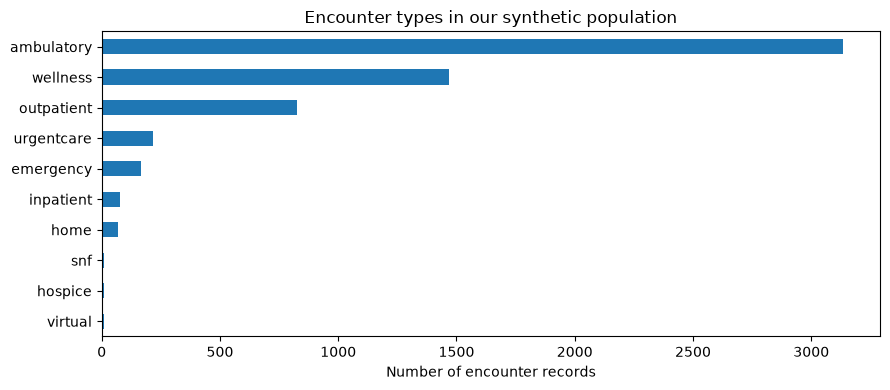

Median encounters/patient: 39
Maximum encounters/patient: 722


In [4]:
encounter_classes = encounters["ENCOUNTERCLASS"].fillna("Unknown").value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
encounter_classes.sort_values().plot.barh(ax=ax)
ax.set(title="Encounter types in our synthetic population", xlabel="Number of encounter records", ylabel="")
plt.tight_layout()
plt.show()
encounters_per_patient = encounters.groupby("PATIENT").size().reindex(patients["Id"], fill_value=0)
print("Median encounters/patient:", int(encounters_per_patient.median()))
print("Maximum encounters/patient:", int(encounters_per_patient.max()))

### Conditions are not always diagnoses

Synthea's `conditions.csv` may include social findings and situations (for example, employment or medication review), not just diseases. **Clinical codes matter more than assumptions based on file names.**

In [5]:
display(conditions[["SYSTEM", "CODE", "DESCRIPTION"]].head(8))
display(conditions["DESCRIPTION"].value_counts().head(10).rename_axis("condition_or_finding").reset_index(name="records"))

,SYSTEM,CODE,DESCRIPTION
0,SNOMED-CT,224299000,Received higher education (finding)
1,SNOMED-CT,713458007,Lack of access to transportation (finding)
2,SNOMED-CT,82423001,Chronic pain (finding)
3,SNOMED-CT,278860009,Chronic low back pain (finding)
4,SNOMED-CT,1121000119107,Chronic neck pain (finding)
5,SNOMED-CT,266934004,Transport problem (finding)
6,SNOMED-CT,160903007,Full-time employment (finding)
7,SNOMED-CT,314529007,Medication review due (situation)


,condition_or_finding,records
0,Medication review due (situation),758
1,Stress (finding),307
2,Gingivitis (disorder),305
3,Full-time employment (finding),287
4,Part-time employment (finding),175
5,Viral sinusitis (disorder),128
6,Social isolation (finding),124
7,Limited social contact (finding),120
8,Not in labor force (finding),93
9,Gingival disease (disorder),87


### Observation data can be numeric or categorical

In [6]:
observations_explored = observations.copy()
observations_explored["numeric_value"] = pd.to_numeric(observations_explored["VALUE"], errors="coerce")
value_total = int(observations_explored["VALUE"].notna().sum())
numeric_total = int(observations_explored["numeric_value"].notna().sum())
print(f"Recorded observation values: {value_total:,}")
print(f"Numeric-looking values: {numeric_total:,} ({numeric_total/max(value_total,1):.1%} of nonempty)")
display(observations[["DATE", "CODE", "DESCRIPTION", "VALUE", "UNITS", "TYPE"]].head(8))

Recorded observation values: 75,004
Numeric-looking values: 46,480 (62.0% of nonempty)


,DATE,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2018-01-07T16:36:29Z,8302-2,Body Height,182.6,cm,numeric
1,2018-01-07T16:36:29Z,72514-3,Pain severity - 0-10 verbal numeric rating [Score] - Reported,3.0,{score},numeric
2,2018-01-07T16:36:29Z,29463-7,Body Weight,83.6,kg,numeric
3,2018-01-07T16:36:29Z,39156-5,Body mass index (BMI) [Ratio],25.1,kg/m2,numeric
4,2018-01-07T16:36:29Z,8462-4,Diastolic Blood Pressure,68.0,mm[Hg],numeric
5,2018-01-07T16:36:29Z,8480-6,Systolic Blood Pressure,130.0,mm[Hg],numeric
6,2018-01-07T16:36:29Z,8867-4,Heart rate,83.0,/min,numeric
7,2018-01-07T16:36:29Z,9279-1,Respiratory rate,15.0,/min,numeric


## 2. Follow one synthetic patient's journey

We choose a **moderately active** synthetic patient with several kinds of clinical events. The ID is selected from the actual generated data, not invented.

**Choose the patient.** The selection favors approximately 30 encounters and some clinical variety. For an unusually small population, it falls back to any patient with recorded encounters.

In [7]:
event_counts = pd.DataFrame(index=pd.Index(patients["Id"], name="PATIENT"))
for name in ["encounters", "conditions", "observations", "medications", "procedures"]:
    event_counts[name] = tables[name].groupby("PATIENT").size().reindex(event_counts.index, fill_value=0)
event_counts["event_types_present"] = (event_counts[["conditions", "observations", "medications", "procedures"]] > 0).sum(axis=1)

def select_patient(counts):
    eligible = counts[(counts["encounters"].between(15, 60)) & (counts["conditions"] >= 2)
                      & (counts["observations"] >= 10) & (counts["event_types_present"] >= 3)].copy()
    if eligible.empty:
        eligible = counts[counts["encounters"] > 0].copy()
    if eligible.empty:
        raise ValueError("No patients with encounters are available")
    eligible["distance_from_30_visits"] = (eligible["encounters"] - 30).abs()
    eligible = eligible.sort_values(["distance_from_30_visits", "event_types_present", "observations"],
                                    ascending=[True, False, False])
    return eligible.index[0]

patient_id = select_patient(event_counts)
print("Selected patient ID (shortened for display):", str(patient_id)[:8] + "…")
display(event_counts.loc[[patient_id]].reset_index(drop=True))
person_demo = patients.loc[patients["Id"] == patient_id, [c for c in ["BIRTHDATE", "GENDER", "RACE", "STATE"] if c in patients]].copy()
display(person_demo.reset_index(drop=True))

Selected patient ID (shortened for display): 1f982352…


,encounters,conditions,observations,medications,procedures,event_types_present
0,30,38,539,19,109,4


,BIRTHDATE,GENDER,RACE,STATE
0,1994-09-24,M,white,Massachusetts


### Reconstruct a longitudinal timeline

In [8]:
# Map the right event timestamp for each Synthea CSV.
event_sources = [
    ("encounters", "START", "Encounter"),
    ("conditions", "START", "Condition / finding"),
    ("observations", "DATE", "Observation"),
    ("medications", "START", "Medication"),
    ("procedures", "START", "Procedure"),
]
parts = []
for name, date_column, label in event_sources:
    df = tables[name]
    if date_column not in df.columns:
        print(f"No {date_column} in {name}; verify your Synthea CSV version")
        continue
    records = df.loc[df["PATIENT"] == patient_id].copy()
    records["event_date"] = pd.to_datetime(records[date_column], utc=True, errors="coerce", format="mixed")
    records["event_type"] = label
    records["description"] = records["DESCRIPTION"].fillna("(no description)")
    parts.append(records[["event_date", "event_type", "description"]])

timeline = (pd.concat(parts, ignore_index=True)
            .dropna(subset=["event_date"])
            .sort_values("event_date").reset_index(drop=True))
print(f"Timeline: {len(timeline):,} dated events (including procedures)")
print("Event type counts:")
display(timeline["event_type"].value_counts().rename_axis("type").reset_index(name="count"))
print("Earliest events:")
display(timeline.head(10))
print("Most recent events (last 10):")
display(timeline.tail(10))

Timeline: 735 dated events (including procedures)
Event type counts:


,type,count
0,Observation,539
1,Procedure,109
2,Condition / finding,38
3,Encounter,30
4,Medication,19


Earliest events:


,event_date,event_type,description
0,1995-10-04 00:00:00+00:00,Condition / finding,Chronic sinusitis (disorder)
1,1995-10-04 11:05:54+00:00,Encounter,Encounter for symptom (procedure)
2,2012-11-17 00:00:00+00:00,Condition / finding,Serving in military service (finding)
3,2012-11-17 00:00:00+00:00,Condition / finding,Received higher education (finding)
4,2012-11-17 11:05:54+00:00,Encounter,General examination of patient (procedure)
5,2013-11-23 00:00:00+00:00,Condition / finding,Stress (finding)
6,2013-11-23 00:00:00+00:00,Condition / finding,Full-time employment (finding)
7,2013-11-23 11:05:54+00:00,Encounter,General examination of patient (procedure)
8,2014-02-03 00:00:00+00:00,Condition / finding,Chronic neck pain (finding)
9,2014-02-03 00:00:00+00:00,Condition / finding,Chronic low back pain (finding)


Most recent events (last 10):


,event_date,event_type,description
725,2026-02-14 11:43:57+00:00,Procedure,Removal of supragingival plaque and calculus from all teeth using dental instrument (p...
726,2026-02-14 12:16:01+00:00,Procedure,Removal of subgingival plaque and calculus from all teeth using dental instrument (pro...
727,2026-02-14 12:52:40+00:00,Procedure,Examination of gingivae (procedure)
728,2026-02-14 12:52:40+00:00,Procedure,Dental plain X-ray bitewing (procedure)
729,2026-02-14 13:44:09+00:00,Medication,sodium fluoride 0.0272 MG/MG Oral Gel
730,2026-02-14 13:44:09+00:00,Procedure,Dental fluoride treatment (procedure)
731,2026-02-14 14:13:35+00:00,Procedure,Oral health education (procedure)
732,2026-09-24 11:05:54+00:00,Observation,QALY
733,2026-09-24 11:05:54+00:00,Observation,DALY
734,2026-09-24 11:05:54+00:00,Observation,QOLS


Let's **plot only encounters, conditions, and procedures by year**.

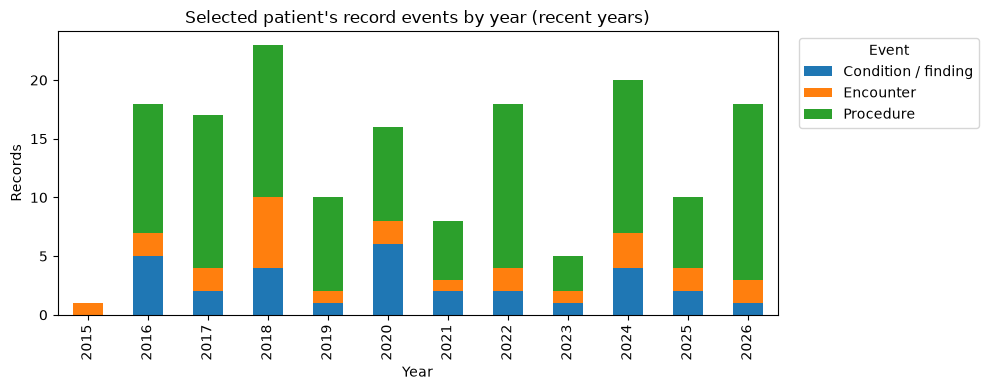

In [9]:
show_types = ["Encounter", "Condition / finding", "Procedure"]
plot_events = timeline.loc[timeline["event_type"].isin(show_types)].copy()
plot_events["year"] = plot_events["event_date"].dt.year
annual = plot_events.groupby(["year", "event_type"]).size().unstack(fill_value=0)
if not annual.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    annual.tail(12).plot.bar(stacked=True, ax=ax)
    ax.set(title="Selected patient's record events by year (recent years)", xlabel="Year", ylabel="Records")
    ax.legend(title="Event", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()
else:
    print("No dated encounter/condition/procedure events to chart")

Select a **single code + unit** for **12 most recent measurements**.

Selected measurement: Hemoglobin A1c/Hemoglobin.total in Blood | code=4548-4 | unit=%


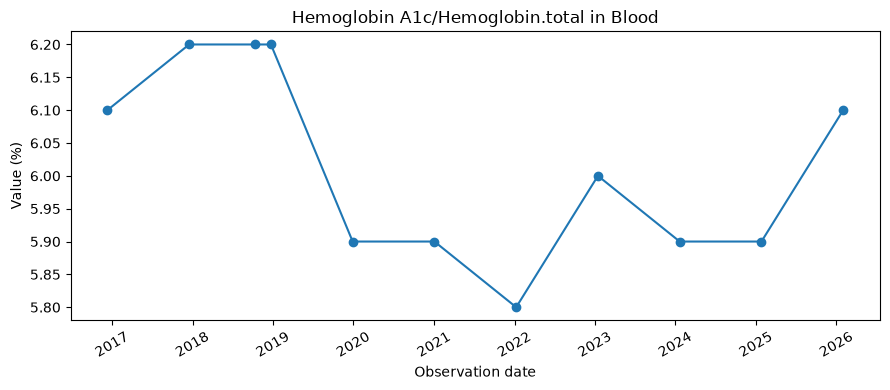

In [10]:
# Known LOINC examples, used only when they actually exist in this patient's observations.
preferred_codes = ["4548-4", "39156-5", "8480-6", "8867-4"]  # HbA1c, BMI, systolic BP, heart rate
person_obs = observations_explored.loc[observations_explored["PATIENT"] == patient_id].copy()
person_obs["event_date"] = pd.to_datetime(person_obs["DATE"], utc=True, errors="coerce", format="mixed")
series = person_obs.dropna(subset=["event_date", "numeric_value", "CODE"]).copy()
series["unit_label"] = series["UNITS"].fillna("(not recorded)")
groups = series.groupby(["CODE", "unit_label"], dropna=False).size()
possible = [key for key in groups.index if groups[key] >= 3]
chosen = next((k for code in preferred_codes for k in possible if k[0] == code), None)
if chosen is None and possible:
    chosen = max(possible, key=lambda k: groups[k])
if chosen is None:
    print("No repeated numeric code/unit series for the selected patient")
else:
    selected = series.loc[(series["CODE"] == chosen[0]) & (series["unit_label"] == chosen[1])]
    selected = selected.sort_values("event_date").tail(12)
    title = str(selected["DESCRIPTION"].iloc[-1])
    print(f"Selected measurement: {title} | code={chosen[0]} | unit={chosen[1]}")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(selected["event_date"], selected["numeric_value"], marker="o")
    ax.set(title=title[:72], xlabel="Observation date", ylabel=f"Value ({chosen[1]})")
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### Why joining healthcare data requires understanding its grain

One encounter can have **many conditions** and **many observations**. A direct join of both detail tables can create a many-to-many multiplication. Instead, aggregate each table to **one row per encounter** and then join.

In [11]:
# Start with one row per encounter for the selected patient.
encounter_view = encounters.loc[
    encounters["PATIENT"] == patient_id, ["Id", "START", "ENCOUNTERCLASS", "DESCRIPTION"]
].copy()
encounter_view = encounter_view.rename(columns={"Id": "ENCOUNTER", "DESCRIPTION": "encounter_description"})
for name in ["conditions", "observations", "medications", "procedures"]:
    event_df = tables[name]
    if "ENCOUNTER" not in event_df:
        continue
    counts = event_df.groupby("ENCOUNTER").size().rename(f"n_{name}")
    encounter_view = encounter_view.merge(counts, left_on="ENCOUNTER", right_index=True,
                                          how="left", validate="one_to_one")
    encounter_view[f"n_{name}"] = encounter_view[f"n_{name}"].fillna(0).astype(int)

assert encounter_view["ENCOUNTER"].is_unique
assert len(encounter_view) == int(event_counts.loc[patient_id, "encounters"])
print("One row per encounter after safe aggregation and joins:")
display(encounter_view.sort_values("START").tail(8).drop(columns="ENCOUNTER"))
example = encounter_view.loc[(encounter_view["n_conditions"] > 0) & (encounter_view["n_observations"] > 0)]
if not example.empty:
    r = example.sort_values("n_conditions", ascending=False).iloc[0]
    print(f"Example encounter: {r.n_conditions} conditions × {r.n_observations} observations "
          f"= {r.n_conditions * r.n_observations} potential rows in a naive detail-level join")

One row per encounter after safe aggregation and joins:


,START,ENCOUNTERCLASS,encounter_description,n_conditions,n_observations,n_medications,n_procedures
2510,2023-01-14T11:05:54Z,wellness,General examination of patient (procedure),1,40,1,3
2511,2024-01-20T11:05:54Z,wellness,General examination of patient (procedure),3,41,1,6
2512,2024-02-03T11:05:54Z,ambulatory,Encounter for check up (procedure),0,0,0,7
2513,2024-09-28T02:05:54Z,ambulatory,Encounter for symptom (procedure),1,1,0,0
2514,2025-01-25T11:05:54Z,wellness,General examination of patient (procedure),1,46,1,5
2515,2025-07-05T23:05:54Z,ambulatory,Encounter for symptom (procedure),1,1,0,1
2516,2026-01-31T11:05:54Z,wellness,General examination of patient (procedure),1,53,1,7
2517,2026-02-14T11:05:54Z,ambulatory,Encounter for check up (procedure),0,0,1,8


Example encounter: 5 conditions × 42 observations = 210 potential rows in a naive detail-level join


## 3. Explore quality and clinical meaning

**Data-quality checks** In healthcare, missing values and unusual observations often have meaning.

- A missing `DEATHDATE` doesn't mean the field is broken.
- A missing observation `ENCOUNTER` may be valid in Synthea.
- A value of zero is **not** a substitute for a missing laboratory test.
- Codes, dates, and units must stay attached to measurements.

In [12]:
print("Duplicate patient IDs:", int(patients["Id"].duplicated().sum()))
print("Duplicate encounter IDs:", int(encounters["Id"].duplicated().sum()))
known_patients = set(patients["Id"].dropna())
known_encounters = set(encounters["Id"].dropna())
checks = []
for name in ["encounters", "conditions", "observations", "medications", "procedures"]:
    df = tables[name]
    d = {"table": name,
         "unknown_patient_reference": int((df["PATIENT"].notna() & ~df["PATIENT"].isin(known_patients)).sum())}
    if "ENCOUNTER" in df:
        d["missing_encounter_reference"] = int(df["ENCOUNTER"].isna().sum())
        d["unknown_nonempty_encounter_reference"] = int((df["ENCOUNTER"].notna() &
                                                           ~df["ENCOUNTER"].isin(known_encounters)).sum())
    checks.append(d)
quality_df = pd.DataFrame(checks)
for col in ["missing_encounter_reference", "unknown_nonempty_encounter_reference"]:
    quality_df[col] = quality_df[col].map(lambda v: "N/A" if pd.isna(v) else int(v))
display(quality_df)

Duplicate patient IDs: 0
Duplicate encounter IDs: 0


,table,unknown_patient_reference,missing_encounter_reference,unknown_nonempty_encounter_reference
0,encounters,0,N/A,N/A
1,conditions,0,0,0
2,observations,0,3204,0
3,medications,0,0,0
4,procedures,0,0,0


In [13]:
# A clinical event must belong to the same patient as its referenced encounter.
encounter_owner = encounters.drop_duplicates("Id").set_index("Id")["PATIENT"]
owner_checks = []
for name in ["conditions", "observations", "medications", "procedures"]:
    df = tables[name]
    if "ENCOUNTER" in df:
        linked = df.loc[df["ENCOUNTER"].notna()]
        parent_patient = linked["ENCOUNTER"].map(encounter_owner)
        mismatches = parent_patient.notna() & (parent_patient != linked["PATIENT"])
        owner_checks.append({"table": name, "encounter_links": len(linked),
                             "patient_encounter_mismatches": int(mismatches.sum())})
display(pd.DataFrame(owner_checks))

,table,encounter_links,patient_encounter_mismatches
0,conditions,4070,0
1,observations,71800,0
2,medications,4454,0
3,procedures,16777,0


In [14]:
def missingness(df):
    return pd.DataFrame({"missing_count": df.isna().sum(),
                         "missing_percent": df.isna().mean().mul(100).round(1)})             .sort_values("missing_percent", ascending=False)
print("Missing fields in observations:")
display(missingness(observations).head(10))
print("Missing units by observation TYPE (not all types need numeric units):")
if "TYPE" in observations:
    display(pd.crosstab(observations["TYPE"].fillna("(missing TYPE)"),
                        observations["UNITS"].isna(), rownames=["TYPE"],
                        colnames=["UNITS missing?"]))

Missing fields in observations:


,missing_count,missing_percent
UNITS,22642,30.2
ENCOUNTER,3204,4.3
CATEGORY,3204,4.3
DATE,0,0.0
PATIENT,0,0.0
CODE,0,0.0
DESCRIPTION,0,0.0
VALUE,0,0.0
TYPE,0,0.0


Missing units by observation TYPE (not all types need numeric units):


UNITS missing?,False,True
TYPE,,
numeric,45275,0
text,7087,22642


## 4. Normalization and feature engineering

There are **three different meanings of normalization** you should separate:

1. **Clinical terminology / unit harmonization:** use coded concepts and consistent units. Two descriptions may refer to the same concept; two units may represent different scales.
2. **Database normalization:** retain distinct tables and their keys to avoid repeated attributes and unreliable joins.
3. **ML feature scaling:** transforms numeric feature ranges (for example, z-scores), but **fit scaling parameters only on the training data** to prevent leakage.

We will demonstrate (1), then create a small patient-level feature table.

In [15]:
# How many different recorded units are associated with the same observation code?
unit_profiles = (
    observations.dropna(subset=["CODE", "UNITS"])
    .groupby(["CODE", "DESCRIPTION"], dropna=False)["UNITS"]
    .nunique().rename("number_of_distinct_units")
    .reset_index().sort_values("number_of_distinct_units", ascending=False)
)
print("Observation concepts using multiple units (inspect before converting):")
display(unit_profiles.query("number_of_distinct_units > 1").head(10))
print("Example conditions with terminology codes:")
display(conditions[["SYSTEM", "CODE", "DESCRIPTION"]].drop_duplicates().head(8))

Observation concepts using multiple units (inspect before converting):


,CODE,DESCRIPTION,number_of_distinct_units
91,5799-2,Leukocyte esterase [Presence] in Urine by Test strip,2
152,788-0,Erythrocyte [DistWidth] in Blood by Automated count,2
39,25428-4,Glucose [Presence] in Urine by Test strip,2
20,20454-5,Protein [Presence] in Urine by Test strip,2
84,5770-3,Bilirubin.total [Presence] in Urine by Test strip,2
172,89579-7,Troponin I.cardiac [Mass/volume] in Serum or Plasma by High sensitivity method,2
66,33914-3,Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based f...,2
38,2514-8,Ketones [Presence] in Urine by Test strip,2
89,5794-3,Hemoglobin [Presence] in Urine by Test strip,2
95,5811-5,Specific gravity of Urine by Test strip,2


Example conditions with terminology codes:


,SYSTEM,CODE,DESCRIPTION
0,SNOMED-CT,224299000,Received higher education (finding)
1,SNOMED-CT,713458007,Lack of access to transportation (finding)
2,SNOMED-CT,82423001,Chronic pain (finding)
3,SNOMED-CT,278860009,Chronic low back pain (finding)
4,SNOMED-CT,1121000119107,Chronic neck pain (finding)
5,SNOMED-CT,266934004,Transport problem (finding)
6,SNOMED-CT,160903007,Full-time employment (finding)
7,SNOMED-CT,314529007,Medication review due (situation)


### Controlled unit-conversion illustration

For **glucose only**, approximately `1 mmol/L = 18.0182 mg/dL`. The two illustrative measurements below use different units but are roughly comparable. 

In [16]:
# Illustrative values only; not imported patient results.
toy_glucose = pd.DataFrame({"example": ["A", "B"], "value": [110.0, 6.1],
                            "unit": ["mg/dL", "mmol/L"]})
toy_glucose["glucose_mg_dL"] = np.where(toy_glucose["unit"].eq("mmol/L"),
                                        toy_glucose["value"] * 18.0182,
                                        toy_glucose["value"])
display(toy_glucose)

,example,value,unit,glucose_mg_dL
0,A,110.0,mg/dL,110.00000
1,B,6.1,mmol/L,109.91102


### Engineer a **time-aware** patient-level feature table

We will calculate:

- Eligibility (alive at the cutoff) and age **only for those alive at cutoff**
- Encounters in the preceding 365 days
- Emergency encounters in the preceding 365 days
- Number of distinct coded findings recorded **before** the cutoff
- Latest HbA1c measurement when available **before** the cutoff and recorded in `%`

**Key principle:** Only use information available **before the cutoff**. A model trained on later observations would be learning from the future (data leakage).

In [17]:
# Freeze one reproducible as-of date based on the generated data, not the wall clock.
encounter_time = pd.to_datetime(encounters["START"], utc=True, errors="coerce", format="mixed")
as_of = encounter_time.max() + pd.Timedelta(days=1)
assert pd.notna(as_of), "No valid encounter timestamps"
window_start = as_of - pd.Timedelta(days=365)
print("As-of (exclusive):", as_of.date())
print("Lookback starts (inclusive):", window_start.date())

visits = encounters[["PATIENT", "START", "ENCOUNTERCLASS"]].copy()
visits["event_time"] = pd.to_datetime(visits["START"], utc=True, errors="coerce", format="mixed")
visits = visits.loc[(visits["event_time"] >= window_start) & (visits["event_time"] < as_of)]
visit_counts = visits.groupby("PATIENT").size().rename("encounters_last_365d")
ed_counts = (visits.loc[visits["ENCOUNTERCLASS"].eq("emergency")]
             .groupby("PATIENT").size().rename("emergency_encounters_last_365d"))

findings = conditions[["PATIENT", "START", "SYSTEM", "CODE"]].copy()
findings["event_time"] = pd.to_datetime(findings["START"], utc=True, errors="coerce", format="mixed")
findings = findings.loc[findings["event_time"].notna() & (findings["event_time"] < as_of)]
findings["coded_concept"] = findings["SYSTEM"].astype("string").fillna("Unknown") + ":" + findings["CODE"].astype("string").fillna("Unknown")
distinct_findings = findings.groupby("PATIENT")["coded_concept"].nunique().rename("distinct_findings_before_cutoff")

labs = observations_explored.loc[observations_explored["CODE"].eq("4548-4") &
                                  observations_explored["UNITS"].eq("%")].copy()
labs["event_time"] = pd.to_datetime(labs["DATE"], utc=True, errors="coerce", format="mixed")
labs = labs.loc[labs["event_time"].notna() & (labs["event_time"] < as_of) & labs["numeric_value"].notna()]
latest_hba1c = (labs.sort_values("event_time").drop_duplicates("PATIENT", keep="last")
                .set_index("PATIENT")["numeric_value"].rename("latest_hba1c_percent"))

features = patients[["Id", "BIRTHDATE", "DEATHDATE", "GENDER"]].rename(columns={"Id": "PATIENT"}).copy()
born = pd.to_datetime(features["BIRTHDATE"], errors="coerce")
died = pd.to_datetime(features["DEATHDATE"], errors="coerce")
cutoff_day = as_of.tz_convert(None).normalize()
features["age_at_cutoff"] = cutoff_day.year - born.dt.year - (
    (born.dt.month > cutoff_day.month) |
    ((born.dt.month == cutoff_day.month) & (born.dt.day > cutoff_day.day))
).astype("Int64")
features["alive_at_cutoff"] = died.isna() | died.ge(cutoff_day)
# Being born before the cutoff matters too: future-born patients are not eligible.
features["alive_at_cutoff"] &= born.le(cutoff_day)
features["age_at_cutoff"] = features["age_at_cutoff"].where(features["alive_at_cutoff"], pd.NA)
features = features.drop(columns=["BIRTHDATE", "DEATHDATE"])
for series in [visit_counts, ed_counts, distinct_findings, latest_hba1c]:
    features = features.merge(series, left_on="PATIENT", right_index=True,
                              how="left", validate="one_to_one")
for col in ["encounters_last_365d", "emergency_encounters_last_365d", "distinct_findings_before_cutoff"]:
    features[col] = features[col].fillna(0).astype(int)

assert features["PATIENT"].is_unique
assert len(features) == len(patients)
print(f"Patient feature table: {len(features)} total records (one row per person)")
print("Alive at cutoff:", int(features["alive_at_cutoff"].sum()))
# For a real training cohort, eligibility and outcome definitions need much more rigor.
preview_features = features.loc[features["alive_at_cutoff"]].head(10).copy()
preview_features["PATIENT"] = preview_features["PATIENT"].str.slice(0, 8) + "…"
display(preview_features)
print("Patients without an HbA1c measurement before cutoff:", int(features["latest_hba1c_percent"].isna().sum()))

As-of (exclusive): 2026-10-25
Lookback starts (inclusive): 2025-10-25
Patient feature table: 115 total records (one row per person)
Alive at cutoff: 100


,PATIENT,GENDER,age_at_cutoff,alive_at_cutoff,encounters_last_365d,emergency_encounters_last_365d,distinct_findings_before_cutoff,latest_hba1c_percent
0,a35dfdc9…,M,30,True,0,0,15,<NA>
2,f1f05592…,F,43,True,0,0,23,6.2
3,7a58a941…,F,69,True,6,1,20,<NA>
4,c4d5d909…,M,48,True,2,0,25,6.0
5,10ca2e4f…,F,22,True,11,1,15,<NA>
6,d545798e…,F,28,True,7,0,15,<NA>
7,5393ea7f…,M,52,True,2,0,30,<NA>
8,711b282e…,F,64,True,1,0,20,6.3
9,3c4b499b…,F,80,True,3,0,34,7.3
10,595f9fb9…,M,54,True,4,0,27,4.0


Patients without an HbA1c measurement before cutoff: 62


## Wrap-up: What makes healthcare data AI-ready?

**One visual journey:**

```text
Synthea patients + encounters + conditions + observations + medications + procedures
       ↓ Understand terms, grains, codes and units
       ↓ Validate identity links, time and missingness
       ↓ Normalize clinical concepts and consistent measurement units
       ↓ Aggregate to the correct grain without row multiplication
       ↓ Engineer features using only information before the prediction time
       ↓ Define outcome labels, evaluation and safeguards
```

### Five takeaways

1. **Clinical context matters.** A value alone rarely tells the full story.
2. **Healthcare data is longitudinal.** Patient and encounter IDs connect events over time.
3. **Missingness isn't always an error.** Different fields have different meanings.
4. **Feature engineering is problem- and time-dependent.** Avoid row multiplication and leakage.
5. **Unstructured text requires careful interpretation.** Especially negation and provenance.

### Suggested closing line

> “Before asking what model to build, first ask: what does this data actually mean, when was it known, and how can we trust it?”

**Resources:** [Synthea](https://github.com/synthetichealth/synthea) · [Synthea CSV dictionary](https://github.com/synthetichealth/synthea/wiki/CSV-File-Data-Dictionary) · [Pandas](https://pandas.pydata.org/docs/)

*Use for education and prototype testing only. Synthea data does not establish model performance on real patients.*